# LSTM Practice Implementation

## Configuring MPS

In [39]:
import torch
import torch.nn as nn

#Set the device automatically: Cuda/Mps
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


## Viewing the CSV

In [40]:
import pandas as pd

df = pd.read_csv("rdb5_data.csv")

df.head(5)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_50794/3545351190.py:3: DtypeWarning: Columns (0: TRAILER_ID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("rdb5_data.csv")


,ID,TIMESTAMP,OBJID,UTM_X,UTM_Y,UTM_ANGLE,V,ACC,ACC_LAT,ACC_TAN,CLASS,WIDTH,LENGTH,TRAILER_ID
0,1,0.000000,57687,617396.68,5806787.75,1.526085,7.64,0.7646,-0.7640,0.0323,Car,2.0149,4.4885,NaN
1,2,0.033367,57687,617396.69,5806788.00,1.529885,7.64,0.8675,-0.8671,0.0253,Car,2.0149,4.4885,NaN
2,3,0.066733,57687,617396.69,5806788.26,1.533185,7.64,0.9703,-0.9702,0.0158,Car,2.0149,4.4885,NaN
3,4,0.100100,57687,617396.70,5806788.51,1.536085,7.64,1.0743,-1.0743,-0.0071,Car,2.0149,4.4885,NaN
4,5,0.133467,57687,617396.70,5806788.77,1.538885,7.64,1.1802,-1.1794,-0.0434,Car,2.0149,4.4885,NaN


In [41]:
#considering vehicle classes
print(df['CLASS'].value_counts())

CLASS
Car               1262670
Pedestrian         185361
Medium Vehicle     148991
Bicycle             79396
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


## Filtering the Data

In [42]:
#keeping only vehicle classes
vehicle_classes = [
    "Car",
    "Medium Vehicle",
    "Trailer",
    "Bus",
    "Heavy Vehicle",
    "Motorcycle"
]

df = df[df["CLASS"].isin(vehicle_classes)]

In [43]:
#verification
print(df["CLASS"].value_counts())

CLASS
Car               1262670
Medium Vehicle     148991
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


In [53]:
#removal of less the 150 object observations
trajectory_lengths = df.groupby("OBJID").size()
valid_objids = trajectory_lengths[trajectory_lengths >= 150].index
df = df[df["OBJID"].isin(valid_objids)]

## Creating Sliding Windows

In [164]:
# #inspecting total data points amount
# positions = df[["UTM_X", "UTM_Y"]].values
# print(positions.shape)

(1493564, 2)


In [56]:
# #defining input and target (first 60, next 90)
# input_positions = positions[:60]
# target_positions = positions[60:150]

# #verification
# print(input_positions.shape, target_positions.shape)

(60, 2) (90, 2)


In [57]:
# #making coordinates relative to the starting point
# origin = input_positions[0]
# input_relative = input_positions - origin
# target_relative = target_positions - origin

# #verification
# print(input_relative[0])
# print(target_relative[0])

[0. 0.]
[-3.14 14.11]


In [58]:
def make_windows(positions, input_length=60, target_length=90, stride=10):
    inputs = []
    targets = []

    total_length = input_length + target_length

    for start in range(0, len(positions) - total_length + 1, stride):
        window = positions[start:start + total_length]

        input_positions = window[:input_length]
        target_positions = window[input_length:]

        origin = input_positions[0]

        input_relative = input_positions - origin
        target_relative = target_positions - origin

        inputs.append(input_relative)
        targets.append(target_relative)

    return inputs, targets

In [59]:
# inputs, targets = make_windows(positions)

# print(len(inputs))
# print(inputs[0].shape)
# print(targets[0].shape)

149342
(60, 2)
(90, 2)


In [169]:
#define train, validate, test split (70/15/15) by objectID so same vehicle isn't used in train and test (cheating)
import numpy as np

#create array of only unique vehicles, to ensure all observations from the same vehicle remain in the same train, val or test set 
vehicle_ids = df["OBJID"].unique()

np.random.seed(1)

np.random.shuffle(vehicle_ids)

n = len(vehicle_ids)

#splitting the vehicle ids between sets
train_ids = vehicle_ids[:int(0.7 * n)]
val_ids = vehicle_ids[int(0.7 * n):int(0.85 * n)]
test_ids = vehicle_ids[int(0.85 * n):]

#verification
print(len(train_ids))
print(len(val_ids))
print(len(test_ids))

2808
602
602


## Making Train, Val and Test Sets

In [62]:
def create_dataset(df, vehicle_ids):
    inputs = []
    targets = []

    for objid in vehicle_ids:
        #get all obserations of just one vehicle from the df
        vehicle = df[df["OBJID"] == objid]

        #get the just the features of importance (x and y pos)
        positions = vehicle[["UTM_X", "UTM_Y"]].values

        #get the first 60 observations of each window and following 90.
        vehicle_inputs, vehicle_targets = make_windows(positions)

        inputs.extend(vehicle_inputs)
        targets.extend(vehicle_targets)

    return inputs, targets

In [63]:
# defining each set through the creat dataset function using the df and the specific ids attatched to each set 
train_inputs, train_targets = create_dataset(df, train_ids)
val_inputs, val_targets = create_dataset(df, val_ids)
test_inputs, test_targets = create_dataset(df, test_ids)

#validation
print("Train:", len(train_inputs))
print("Validation:", len(val_inputs))
print("Test:", len(test_inputs))

Train: 64452
Validation: 13912
Test: 13515


## Converting Data to PyTorch Tensors

In [64]:
#converting to tensors for pytorch use
train_inputs = torch.tensor(train_inputs, dtype=torch.float32)
train_targets = torch.tensor(train_targets, dtype=torch.float32)

val_inputs = torch.tensor(val_inputs, dtype=torch.float32)
val_targets = torch.tensor(val_targets, dtype=torch.float32)

test_inputs = torch.tensor(test_inputs, dtype=torch.float32)
test_targets = torch.tensor(test_targets, dtype=torch.float32)

In [65]:
#verification
print(train_inputs.shape)
print(train_targets.shape)
print(val_inputs.shape)
print(val_targets.shape)
print(test_inputs.shape)
print(test_targets.shape)

torch.Size([64452, 60, 2])
torch.Size([64452, 90, 2])
torch.Size([13912, 60, 2])
torch.Size([13912, 90, 2])
torch.Size([13515, 60, 2])
torch.Size([13515, 90, 2])


## Making PyTorch Dataset

In [66]:
#the dataset stores data examples and their corresponding labels
#and gives us one example at a time
from torch.utils.data import Dataset

class TrajectoryDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]

In [67]:
train_dataset = TrajectoryDataset(train_inputs, train_targets)
val_dataset = TrajectoryDataset(val_inputs, val_targets)
test_dataset = TrajectoryDataset(test_inputs, test_targets)

In [68]:
# x, y = train_dataset[0]

# print(x.shape)
# print(y.shape)

torch.Size([60, 2])
torch.Size([90, 2])


## Making Pytorch Dataloader

In [170]:
# DataLoader groups examples into batches
from torch.utils.data import DataLoader

# Only shuffle the training data so the model get examples
# in a different order each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Defining LSTM Architecture

In [70]:
class TrajectoryLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=2,
            hidden_size=64, #sensible moderate hyperparameter, however, may change during validation
            batch_first=True
        )

        self.linear = nn.Linear(64, 180)

        #this direct-prediction architecture is a simplified starting point, sequence to sequence may be better later
        #direct prediction: predict all 90 future locations
        #sequence-to-sequence: predict future locations one at a time
    def forward(self, x):
        #pass the input through the LSTM
        output, (hidden, cell) = self.lstm(x)
    
        #remove the unnecessary layer dimension
        hidden = hidden.squeeze(0)
    
        #produce 180 numbers
        output = self.linear(hidden)
    
        #turn those 180 numbers into coordinates, -1 in case last batch size isn't the full 32
        output = output.reshape(-1, 90, 2)
    
        return output
        
        #If x = (32, 60, 2), then output = (32, 60, 64), hidden = (1, 32, 64), cell   = (1, 32, 64)
        # output — the hidden state at every one of the 60 input timesteps
        # hidden — the final hidden state
        # cell — the final cell state


## Instantiating Model

In [71]:
model = TrajectoryLSTM()

## Defining Loss Function (MSE)

In [72]:
#returns PyTorch Tensor, because PyTorch needs to track the computational graph so that it can later calc gradients
#computational graph is the trail of how the value came to be input->LSTM->prediction->MSEloss
#loss.item() gives the associated float
loss_fn = nn.MSELoss()

## Optimiser

In [73]:
#utilising PyTorch's Adam Optimiser 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Completing One Full Training Cycle on a Batch

In [ ]:
# # reset optimiser gradient
# optimizer.zero_grad()

# # make new prediction using batch
# prediction = model(x_batch)

# #calculate loss
# loss = loss_fn(prediction, y_batch)

# #calculate gradients for optimisation step
# loss.backward()

# #update weights accordingly 
# optimizer.step()

## Full Epoch

In [ ]:
# model.train()

# total_loss = 0

# for x_batch, y_batch in train_loader:

#     optimizer.zero_grad()

#     prediction = model(x_batch)

#     loss = loss_fn(prediction, y_batch)

#     loss.backward()

#     optimizer.step()

#     total_loss += loss.item()

# average_loss = total_loss / len(train_loader)

# print("Training loss:", average_loss)

## Multiple Epochs

In [74]:
num_epochs = 20
losses = []

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for x_batch, y_batch in train_loader:

        optimizer.zero_grad()

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    
    losses.append(average_loss)

    print("Epoch:", epoch + 1, "Training loss:", average_loss)

Epoch: 1 Training loss: 38.33710607228149
Epoch: 2 Training loss: 4.420901253619798
Epoch: 3 Training loss: 3.0359817306397865
Epoch: 4 Training loss: 2.6472057917277807
Epoch: 5 Training loss: 2.2720463857165636
Epoch: 6 Training loss: 2.0212807929841223
Epoch: 7 Training loss: 2.079962113152071
Epoch: 8 Training loss: 1.9394741921803496
Epoch: 9 Training loss: 1.7386540229651828
Epoch: 10 Training loss: 1.6474580854547232
Epoch: 11 Training loss: 1.6103812038898468
Epoch: 12 Training loss: 1.5981004162106858
Epoch: 13 Training loss: 1.3769053271331504
Epoch: 14 Training loss: 1.6291245873749405
Epoch: 15 Training loss: 1.344815402424365
Epoch: 16 Training loss: 1.2972502720710952
Epoch: 17 Training loss: 1.3327627228152368
Epoch: 18 Training loss: 1.411135025459247
Epoch: 19 Training loss: 1.3459561416144405
Epoch: 20 Training loss: 1.5090312632378515


## Graphing Loss vs Epoch

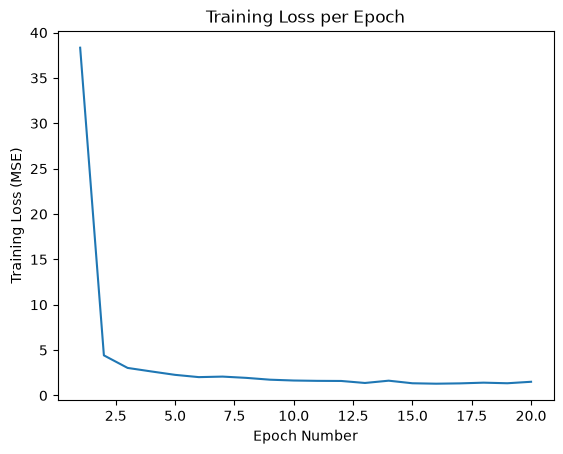

In [160]:
import matplotlib.pyplot as plt
plt.plot(range(1, num_epochs + 1), losses)

plt.xlabel("Epoch Number")
plt.ylabel("Training Loss (MSE)")
plt.title("Training Loss per Epoch")

plt.show()

## Model Evaluation

In [161]:
model.eval()

total_loss = 0

#no gradient calculation/ model is not changing
with torch.no_grad():

    for x_batch, y_batch in val_loader:

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        total_loss += loss.item()

average_val_loss = total_loss / len(val_loader)

print("Validation loss:", average_val_loss)

Validation loss: 1.2857963820641067


## Inference of Unseen Trajectory

In [175]:
print(len(test_inputs))
x_test = test_inputs[500]
y_test = test_targets[500]

#unsqueeze to allow a single example batch
x_test = x_test.unsqueeze(0)

model.eval()

with torch.no_grad():
    prediction = model(x_test)

#remove batch dimension
prediction = prediction.squeeze(0)

13515


In [123]:
#converting tensors to np arrays for plotting
observed = x_test.squeeze(0).numpy()
actual = y_test.numpy()
predicted = prediction.numpy()

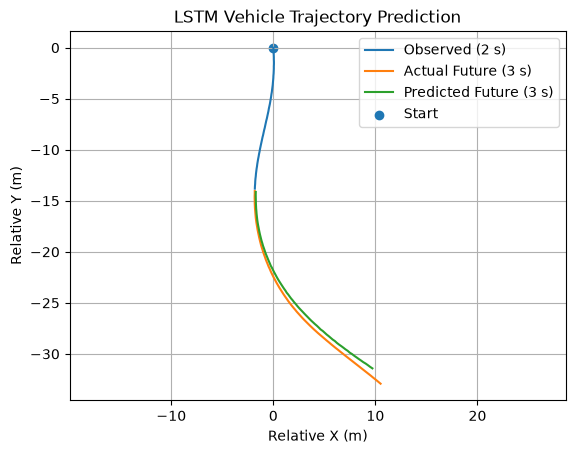

In [129]:
import matplotlib.pyplot as plt

plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

In [177]:
mse = loss_fn(prediction, y_test)

print("MSE:", mse.item())

MSE: 0.3386441469192505
